# 01 – Exploratory Data Analysis & Preprocessing

In [445]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

In [446]:
df = pd.read_csv("../data/hotel_bookings.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [447]:
df.head() # first five rows of the data set

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


#### Class balance on the raw data.

In [448]:
# class balance on the raw data (before cleaning)
print(df["is_canceled"].value_counts())
print((df["is_canceled"].value_counts(normalize=True) * 100).round(2))

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64


In this data set there are 119390 rows and 32 columns. Target variable is `is_canceled` and it contains 62.96% (count:75166) not canceled and 37.04% (count: 44224) canceled data. 

## Duplicates

In [449]:
print("Duplicates:", df.duplicated().sum())
# share of cancellations among the duplicate rows
dup_cancel_rate = df[df.duplicated()]["is_canceled"].mean() * 100
print("Cancellation rate among duplicates:", round(dup_cancel_rate, 2), "%")

Duplicates: 31994
Cancellation rate among duplicates: 63.13 %


In [450]:
df = df.drop_duplicates() 
df.shape

(87396, 32)

From 119,390 rows, 31,994 duplicate rows were removed. Current dataframe shape: (87396, 32). Most of the duplicate rows (63.13%) were canceled bookings.

## Missing values


In [451]:
missing = df.isnull().sum()
missing = missing[missing> 0]
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct
}).sort_values("missing_count", ascending=False) # biggest problem first

missing_table


,missing_count,missing_percent
company,82137,93.98
agent,12193,13.95
country,452,0.52
children,4,0.00


### Missing values

After removing the 31,994 duplicate rows, 87,396 bookings remain. The percentages below are calculated on this cleaned data.

Four columns have missing values: `company`, `agent`, `country` and `children`.

- **company (93.98%)**: missing most likely means the booking was not made through a company. Instead of dropping the column, we convert it into a yes/no feature `has_company`.
- **agent (13.95%)**: missing most likely means the booking was made without a travel agent. Like company, it is an ID number, so we convert it into a yes/no feature `has_agent`.
- **country (0.52%)**: only a few rows are missing, so we fill them with "Unknown" instead of guessing a country.
- **children (4 rows)**: we fill these with 0, as this is the most common and most logical value.

In [452]:
# company: missing replaced with 1 and 0 -> 1 if booked through a company, 0 if not
df["has_company"] = df["company"].notna().astype(int)
# agent: missing replaced with 1 and 0 -> 1 if booked through an agent, 0 if not
df["has_agent"] = df["agent"].notna().astype(int)
# missing country fill with "Unknown"
df["country"] = df["country"].fillna("Unknown")
# Missing children values replaced with 0 
df["children"] = df["children"].fillna(0)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_company,has_agent
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,0,1


In [453]:
# Drop ID columns (company and agent )
df = df.drop(columns=["company", "agent"])

In [454]:
df.isnull().sum().sum()

np.int64(0)

## Invalid rows

In [455]:
df["total_guests"] = df["adults"] + df["children"] + df["babies"] 
(df["total_guests"] == 0).sum()

np.int64(166)

A booking without a guest is impossible. Therefore, these records are invalid and can be removed from the dataset.

In [456]:
# keep only bookings with at least 1 guest.
df = df[df["total_guests"]>0]
df.shape

(87230, 33)

`adr` is the average daily rate: the price per night in euros. A negative price is impossible, so it’s another data error.

In [457]:
# Remove booking with negative price
print((df["adr"] < 0).sum()) 
df = df[df["adr"] >= 0] 
df.shape

1


(87229, 33)

### Outliers in adr

In [458]:
df["adr"].describe()

count    87229.000000
mean       106.519325
std         54.890211
min          0.000000
25%         72.250000
50%         98.200000
75%        134.100000
max       5400.000000
Name: adr, dtype: float64

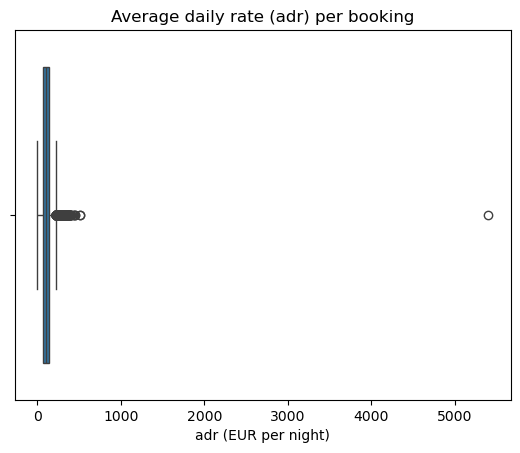

In [459]:
# box plot for 'adr'
sns.boxplot(x=df["adr"])
plt.title("Average daily rate (adr) per booking")
plt.xlabel("adr (EUR per night)")
plt.savefig("../figures/adr_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [460]:
q1 = df["adr"].quantile(0.25)
q3 = df["adr"].quantile(0.75)
iqr = q3 - q1
upper =  q3 + 1.5 * iqr
print("upper fence:", upper)
print("data beyond  upper fence:", (df["adr"]> upper).sum())
print("percentage:", round((df["adr"]> upper).sum()*100/ len(df),1),"%")

upper fence: 226.875
data beyond  upper fence: 2508
percentage: 2.9 %


In [461]:
# remove the single extreme adr value (5,400 EUR), likely a data-entry error
df = df[df["adr"] < 5000] 
df.shape

(87228, 33)

Using the IQR rule, 2,508 bookings (2.9%) exceeded the upper fence of €226.88. These values formed a continuous range up to approximately €500 and were considered genuine high-season or premium bookings; therefore, they were retained. However, one booking with an `adr` value of €5,400, approximately ten times higher than any other value, was identified as a likely data-entry error and removed.

## Exploratory Data Analysis
### Target variable

In [462]:
# class balance on the cleaned data
print(df["is_canceled"].value_counts())
print((df["is_canceled"].value_counts(normalize=True) * 100).round(2))

is_canceled
0    63220
1    24008
Name: count, dtype: int64
is_canceled
0    72.48
1    27.52
Name: proportion, dtype: float64


After cleaning, 72.48% of bookings were not canceled, while 27.52% were canceled. Before cleaning, the cancellation rate was 37.04%. This decrease is explained by the duplicate rows: 63.13% of the removed duplicates were canceled bookings.

Since the data is imbalanced, a model that always predicts ‘not canceled’ would already reach about 72% accuracy without finding any cancellations. Therefore, precision, recall, F1-score and ROC-AUC will also be used to evaluate the models.

### Overview of numeric variables

In [463]:
# numeric measurement columns (except target and dates)
num_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "adr"
]

df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
lead_time,87228.0,79.970216,86.058654,0.0,11.00,49.0,125.0,737.0
stays_in_weekend_nights,87228.0,1.004586,1.027365,0.0,0.00,1.0,2.0,19.0
stays_in_week_nights,87228.0,2.623905,2.039814,0.0,1.00,2.0,4.0,50.0
adults,87228.0,1.879362,0.621731,0.0,2.00,2.0,2.0,55.0
children,87228.0,0.138900,0.456270,0.0,0.00,0.0,0.0,10.0
babies,87228.0,0.010845,0.113705,0.0,0.00,0.0,0.0,10.0
previous_cancellations,87228.0,0.030403,0.369349,0.0,0.00,0.0,0.0,26.0
previous_bookings_not_canceled,87228.0,0.184035,1.733042,0.0,0.00,0.0,0.0,72.0
booking_changes,87228.0,0.268469,0.710612,0.0,0.00,0.0,0.0,18.0
days_in_waiting_list,87228.0,0.746309,10.001115,0.0,0.00,0.0,0.0,391.0


The table above shows several unusually high values. The maximum number of `adults` is 55, while the maximum numbers of `children` and `babies` are both 10. These values are unrealistic for a single booking and may indicate data-entry errors.

The maximum value of `required_car_parking_spaces` is 8. Although unusual, this is possible for a large group travelling in several vehicles. The maximum `lead_time` is 737 days, which may occur when bookings are made well in advance for special events. Similarly, `stays_in_week_nights` has a maximum of 50 nights, which is unusual but possible for long-term stays. The maximum `days_in_waiting_list` is 391 days, which is also unusually high but may be valid.

Therefore, the extreme values in `required_car_parking_spaces`, `lead_time`, `stays_in_week_nights`, and `days_in_waiting_list` were retained because they are unusual but possible. The guest-related columns (`adults`, `children`, and `babies`) were investigated further using their frequency distributions to identify potential data-entry errors.

In [464]:
# Children , babies, adults frequencies 
print(df["children"].value_counts().sort_index())
print(df["babies"].value_counts().sort_index())
print(df["adults"].value_counts().sort_index())

children
0.0     78864
1.0      4695
2.0      3593
3.0        75
10.0        1
Name: count, dtype: int64
babies
0     86314
1       897
2        15
9         1
10        1
Name: count, dtype: int64
adults
0       219
1     16503
2     64495
3      5935
4        60
5         2
6         1
10        1
20        2
26        5
27        2
40        1
50        1
55        1
Name: count, dtype: int64


The frequency distributions show clear gaps: `children` jumps from 3 to 10, `babies` from 2 to 9, and `adults` from 6 to 10, with values reaching up to 55. These isolated values are considered unrealistic for a single booking and are treated as potential data-entry errors. Therefore, bookings with more than 4 `adults`, more than 3 `children`, or more than 2 `babies` were removed, resulting in 19 bookings being removed. The limit of 4 `adults` is supported by the dataset paper, which reports that the City Hotel never has more than 4 adults per booking.

The 219 bookings with 0 `adults` were retained. Most of these bookings have exactly 2 `children`, and many belong to the `Transient-Party` customer type. Therefore, they may represent children's rooms associated with family bookings and were not automatically treated as invalid.

In [465]:
# remove unrealistic guest numbers 
# more than 4 adults, more than 3 children or more than 2 babies
df = df[(df["adults"] <= 4) & (df["children"] <= 3) & (df["babies"] <= 2)]
df.shape

(87209, 33)

## Exploratory Data Analysis

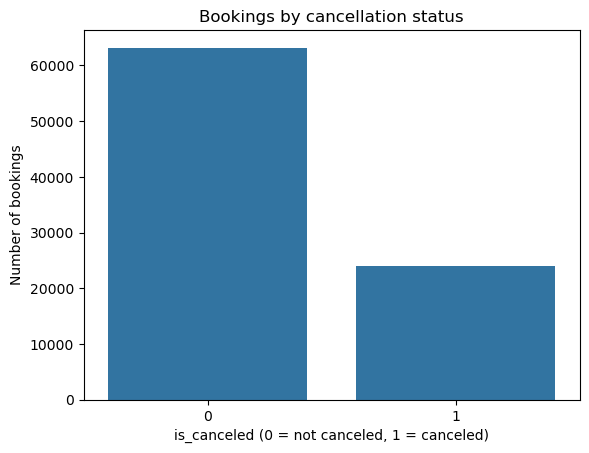

In [466]:
# class balance after cleaning
sns.countplot(x="is_canceled", data=df)
plt.title("Bookings by cancellation status")
plt.xlabel("is_canceled (0 = not canceled, 1 = canceled)")
plt.ylabel("Number of bookings")
plt.savefig("../figures/class_balance.png", dpi=300, bbox_inches="tight")
plt.show()

The bar chart shows that non-canceled bookings (63,206) clearly outnumber canceled bookings (24,003) after cleaning. This confirms the moderate class imbalance observed in the dataset.

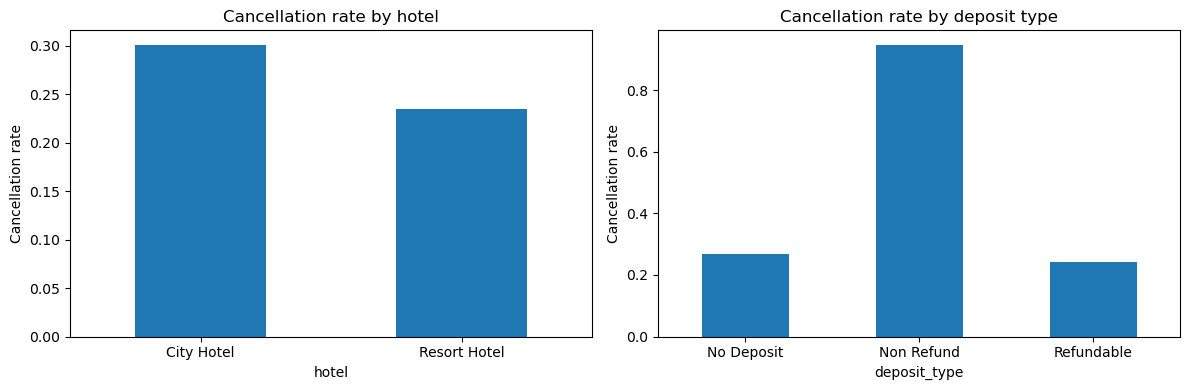

In [467]:
# cancellation rate by hotel and by deposit type
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("hotel")["is_canceled"].mean().plot(kind="bar", ax=axes[0], title="Cancellation rate by hotel")
df.groupby("deposit_type")["is_canceled"].mean().plot(kind="bar", ax=axes[1], title="Cancellation rate by deposit type")
for ax in axes:
    ax.set_ylabel("Cancellation rate")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../figures/cancel_rate_hotel_deposit.png", dpi=300, bbox_inches="tight")
plt.show()

The City Hotel has a higher cancellation rate (30.1%) than the Resort Hotel (23.4%). Surprisingly, bookings with a `Non-Refund` deposit have the highest cancellation rate (94.7%), compared with 26.7% for `No Deposit` and 24.3% for `Refundable` bookings. This unexpected pattern was also discussed in the dataset authors' later work and may be related to group or tour-operator bookings with special conditions. However, `Non-Refund` bookings account for only 1,037 bookings (1.2% of the dataset), so this group is relatively small.

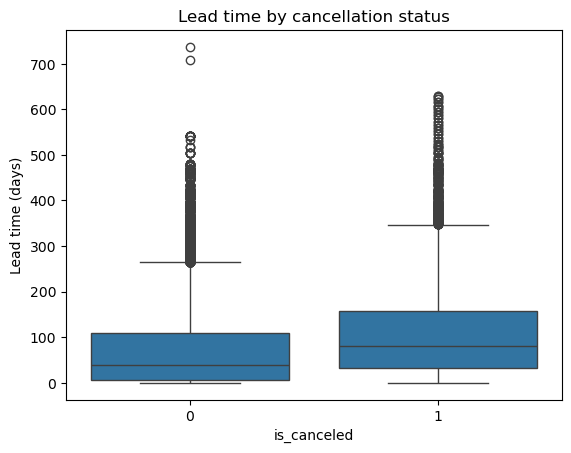

In [468]:
# lead time by cancellation status
sns.boxplot(x="is_canceled", y="lead_time", data=df)
plt.title("Lead time by cancellation status")
plt.xlabel("is_canceled")
plt.ylabel("Lead time (days)")
plt.savefig("../figures/lead_time_by_class.png", dpi=300, bbox_inches="tight")
plt.show()

Canceled bookings tend to have a longer lead time than non-canceled bookings. The median `lead_time` is 80 days for canceled bookings, compared with 38 days for non-canceled bookings. This suggests that `lead_time` may be an important predictor of booking cancellations.

## Preprocessing for modelling

In [469]:
# leakage: these columns are only known AFTER the outcome (dataset paper),
# so they must not be used to predict cancellation
df = df.drop(columns=["reservation_status", "reservation_status_date", "assigned_room_type"])

In [470]:
# new features
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["has_previous_cancellation"] = (df["previous_cancellations"] > 0).astype(int)
df.shape

(87209, 32)

In [471]:
# split data
X = df.drop(columns=["is_canceled"])
y = df["is_canceled"]

# stratified 80/20 split; random_state fixed so both models use the same data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(X_train.shape, X_test.shape)
print("cancel rate train:", round(y_train.mean(), 4), " test:", round(y_test.mean(), 4))

# save for the model notebooks (02 logistic regression, 03 random forest)
pd.concat([X_train, y_train], axis=1).to_csv("../outputs/train.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv("../outputs/test.csv", index=False)

(69767, 31) (17442, 31)
cancel rate train: 0.2751  test: 0.2751
